# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import VisDroneDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 8629


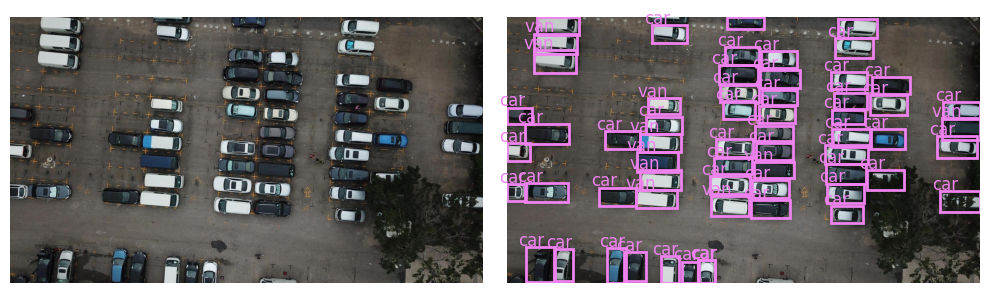

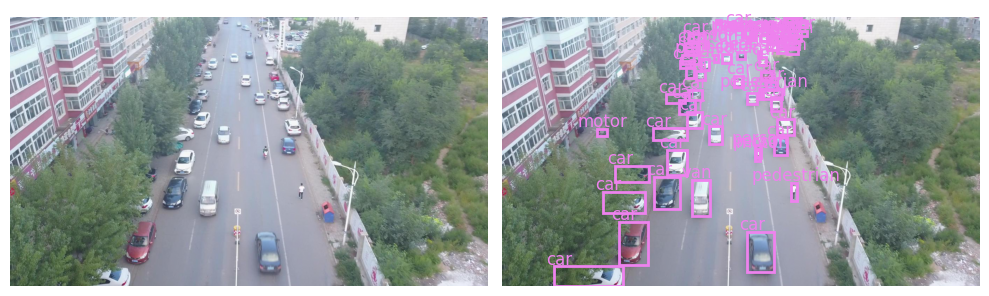

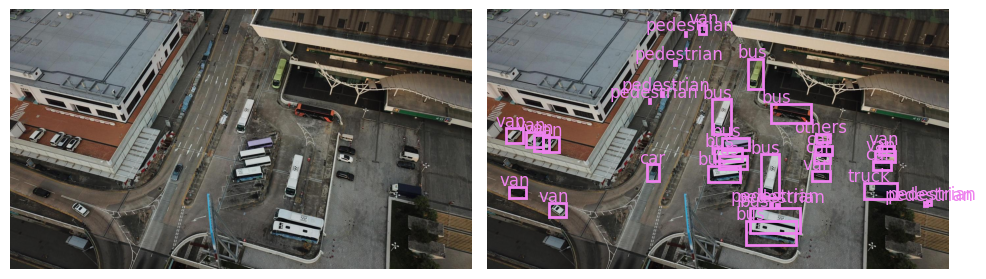

In [ ]:
dataset_config = {
    "data_dir": "./data/VisDrone/images/",
    "annotation_dir": "./data/VisDrone/annotations/",
}
dataset = VisDroneDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

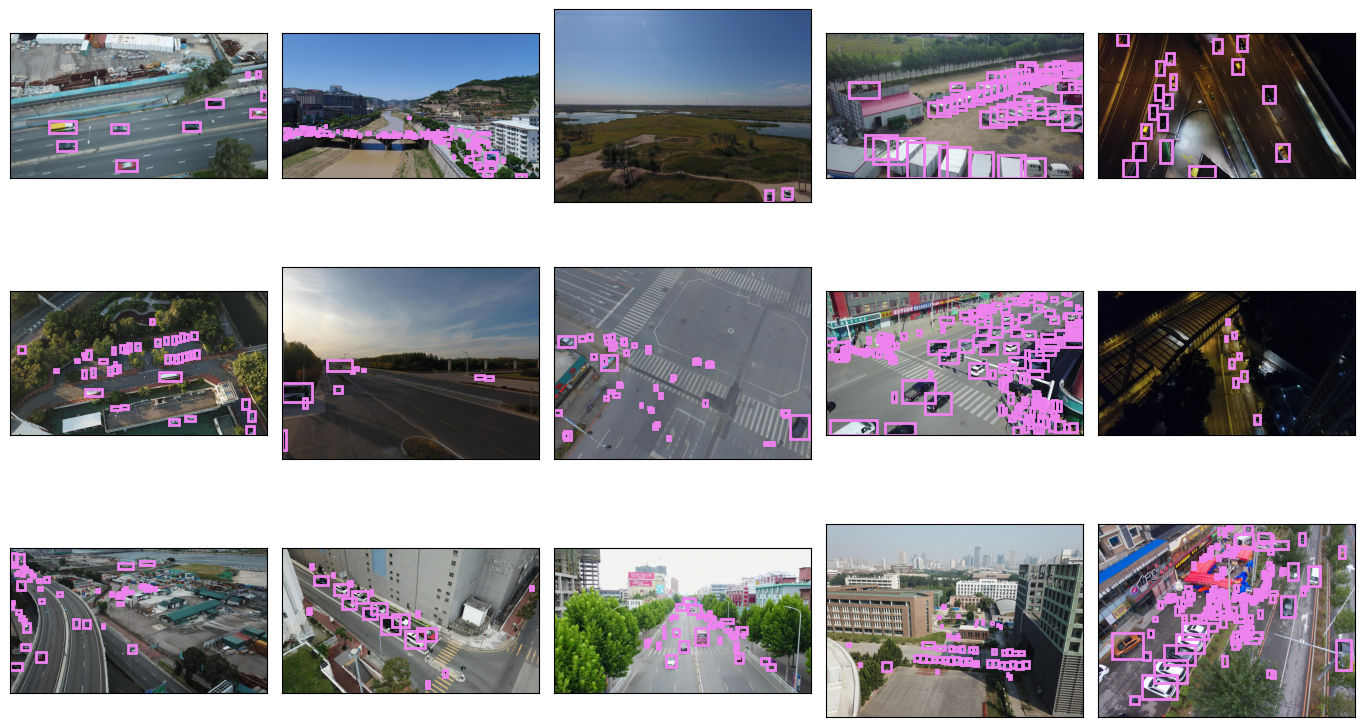

In [7]:
dataset.show_batch(15);

In [8]:
dataset.data_distribution_table()

,Label,Count
0,ignored classes,12369
1,pedestrian,109187
2,person,38560
3,bicycle,13069
4,car,187004
5,van,32702
6,truck,16284
7,tricycle,6387
8,awning-tricycle,4377
9,bus,9117


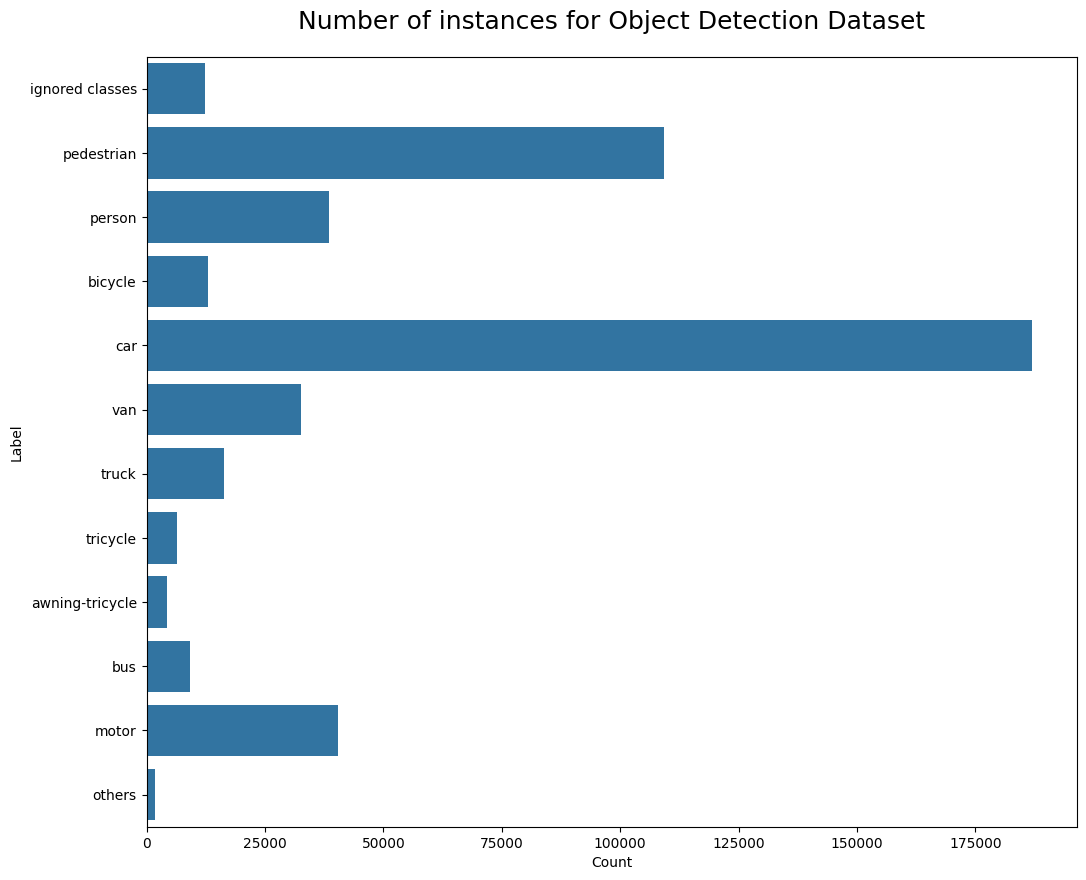

In [9]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/VisDrone/train/images/",
    "annotation_dir": "./data/VisDrone/train/annotations/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = VisDroneDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 6471


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/VisDrone/experiments/"
model_config = {
    "num_classes": 12,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-18 12:17:48,864 INFO Starting training.
training: 100%|██████████| 809/809 [04:35<00:00,  2.93it/s]
2025-04-18 12:22:25,001 INFO epoch: 1, time: 276, loss:  1.13676
testing on train set: 100%|██████████| 809/809 [02:31<00:00,  5.35it/s]
2025-04-18 12:28:58,607 INFO map:0.11471878737211227, map_50:0.19644995033740997, map_75:0.12022999674081802, map_small:0.09464816749095917, map_medium:0.24978549778461456, map_large:0.3403366804122925, mar_1:0.046466533094644547, mar_10:0.12448741495609283, mar_100:0.15187940001487732, mar_small:0.12946563959121704, mar_medium:0.3086896240711212, mar_large:0.36262747645378113, map_per_class:tensor(0.), tensor(0.1454), tensor(0.0220), tensor(0.0173), tensor(0.3976), tensor(0.2008), tensor(0.2245), tensor(0.0422), tensor(0.0195), tensor(0.2293), tensor(0.0742), tensor(0.0038), mar_100_per_class:tensor(0.), tensor(0.2029), tensor(0.0285), tensor(0.0221), tensor(0.4633), tensor(0.2519), tensor(0.3173), tensor(0.0783), tensor(0.0348), tensor(0.2856)

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/VisDrone/val/images/",
    "annotation_dir": "./data/VisDrone/val/annotations/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = VisDroneDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/VisDrone/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 548


2025-04-18 14:13:32,691 INFO Loading checkpoint /home/dragik/data/FAIR_EO/VisDrone/experiments/checkpoint.pth.tar
2025-04-18 14:13:33,045 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/VisDrone/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 69/69 [00:15<00:00,  4.34it/s]


[{'map': 0.14689284563064575,
  'map_50': 0.2463299036026001,
  'map_75': 0.15079915523529053,
  'map_small': 0.12892921268939972,
  'map_medium': 0.2736480236053467,
  'map_large': 0.2548174560070038,
  'mar_1': 0.07563382387161255,
  'mar_10': 0.17088089883327484,
  'mar_100': 0.20280803740024567,
  'mar_small': 0.17865334451198578,
  'mar_medium': 0.35849109292030334,
  'mar_large': 0.28580358624458313,
  'map_per_class': [tensor(0.),
   tensor(0.1617),
   tensor(0.0533),
   tensor(0.0280),
   tensor(0.4750),
   tensor(0.2239),
   tensor(0.1733),
   tensor(0.1085),
   tensor(0.0598),
   tensor(0.3192),
   tensor(0.1341),
   tensor(0.0259)],
  'mar_100_per_class': [tensor(0.),
   tensor(0.2109),
   tensor(0.0810),
   tensor(0.0385),
   tensor(0.5375),
   tensor(0.3106),
   tensor(0.2544),
   tensor(0.1791),
   tensor(0.1827),
   tensor(0.3574),
   tensor(0.1941),
   tensor(0.0875)],
  'classes': [tensor(0, dtype=torch.int32),
   tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.

## Predictions

2025-04-25 06:38:51,195 INFO Loading checkpoint /home/dragik/data/FAIR_EO/VisDrone/experiments/checkpoint.pth.tar
2025-04-25 06:38:51,915 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/VisDrone/experiments/checkpoint.pth.tar at epoch 11


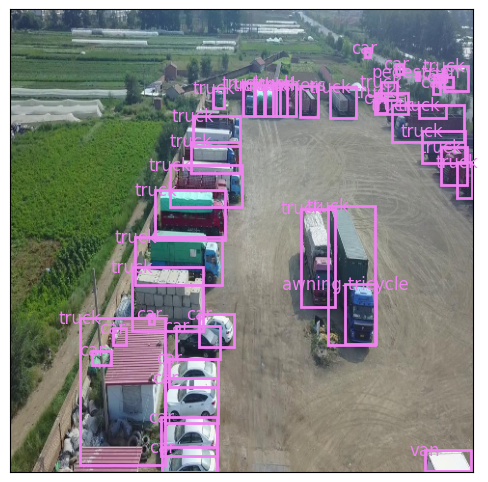

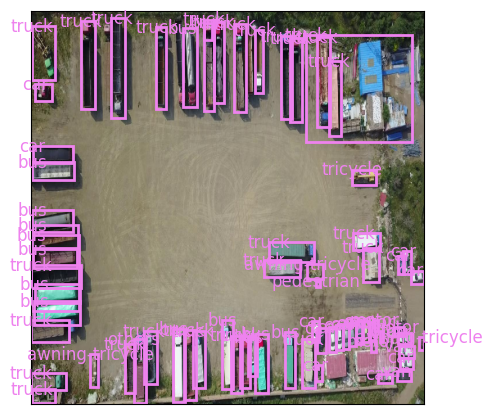

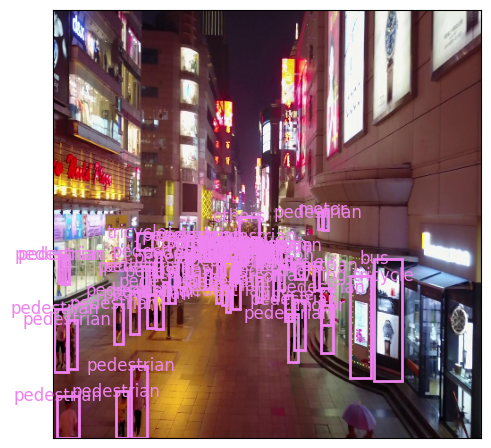

In [ ]:
model_config = {
    "num_classes": 12,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/VisDrone/experiments/checkpoint.pth.tar"
labels = ["ignored classes", "pedestrian", "person","bicycle", "car", "van", "truck", "tricycle", "awning-tricycle", "bus", "motor","others"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/VisDrone/test_dev/images/0000006_01659_d_0000004.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/VisDrone/test_dev/images/0000006_05999_d_0000017.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/VisDrone/test_dev/images/0000074_15298_d_0000030.jpg')
fig = model.detect_objects(image, labels, transform)